## **一、S4-01：Flow Matching 原理与 ODE 采样**

你在 S1 学过从噪声估计反向一步，在 S2 学过把图像压到潜空间，在 S3 已经看过一维时间驱动的二维 Flow 预研。这一课要补上从训练到生成之间最容易断开的推理：**训练时可以随手配对噪声和数据，生成时手里只有噪声。模型从这些配对里究竟学到了什么，又凭什么能把一团噪声变成数据分布？**

| 建议顺序 | 要完成的事 |
| --- | --- |
| 先看结果 | 同一批点从高斯变到两个簇。指出中间点和配对线各表示什么。 |
| 推导主线 | 从线性插值求条件速度，再从平方误差推导边际速度场。 |
| 采样实验 | 亲手算一次 Euler 和 Heun，用解析解和同 NFE 对照复核。 |
| 动手验收 | 实现四个小函数。检查时间方向、批量广播、梯度和第二次求值的位置。 |

前置只需复习 [S1-01 的前向直接加噪与噪声预测](S1_第1周_DDPM原理与MNIST实验.ipynb)、[S2-04 的 latent 链路](S2_第4周_潜空间扩散训练与采样.ipynb) 和 [S3 第九章的 Flow 预研](S3_文本条件CFG与可信评测.ipynb)。学完能从白纸推导训练标签和两种采样更新，并独立解释「配对直线」「学到的向量场」「求解器步数」这三个概念。

### **1. 先看两团点怎样从噪声里出现**

把每张图的潜变量暂时缩成二维坐标。起点从标准高斯采样，终点从两个带抖动的簇随机采样。下面给每个起点分配一个终点，分别取路径的开头、中间和结尾。颜色来自 **终点的簇编号**，仅供看图，起点的颜色并不表示噪声已经带有类别信息。

代码使用 Python、PyTorch、Matplotlib。选现有项目的 Python 内核，从上到下运行。本课点云由固定种子在 CPU 内存中生成，图表留在 Notebook 输出中。若后续自己需要持久化教学点云，按课程分放到项目忽略的 `artifacts/learning/s4_01/`，与正式样本、清单和缓存分开。

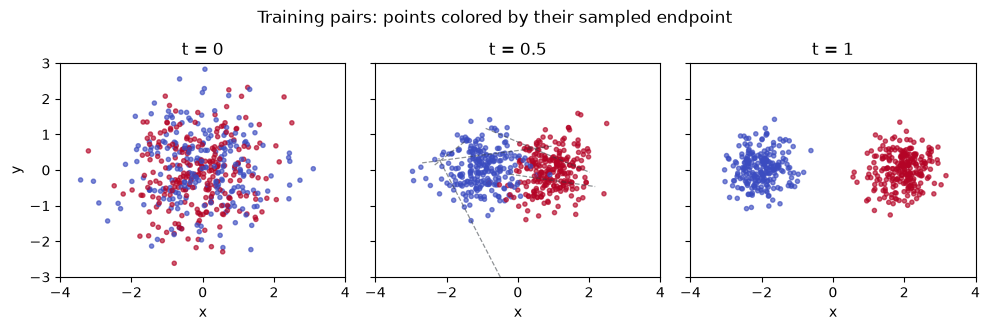

Python 3.12.14 | PyTorch 2.14.1 | CPU float64
seed=4101 | 480 training pairs | points per component=[236, 244]


In [1]:
import math
import sys
from collections.abc import Callable

import matplotlib.pyplot as plt
import torch
from torch import Tensor

dtype = torch.float64
pair_rng = torch.Generator(device="cpu").manual_seed(4101)
b = 480
centers = torch.tensor([[-2.0, 0.0], [2.0, 0.0]], dtype=dtype)
sigma = 0.45
component = torch.randint(2, (b,), generator=pair_rng)
noise = torch.randn(b, 2, generator=pair_rng, dtype=dtype)
clean = centers[component] + sigma * torch.randn(b, 2, generator=pair_rng, dtype=dtype)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.1), sharex=True, sharey=True)
for ax, t in zip(axes, (0.0, 0.5, 1.0), strict=True):
    points = (1.0 - t) * noise + t * clean
    ax.scatter(*points.T, c=component, cmap="coolwarm", s=9, alpha=0.65)
    ax.set(title=f"t = {t:g}", xlim=(-4, 4), ylim=(-3, 3), xlabel="x")
    ax.set_aspect("equal")
for index in range(5):
    segment = torch.stack((noise[index], clean[index]))
    axes[1].plot(*segment.T, "--", color="#343a40", alpha=0.55, linewidth=0.9)
axes[0].set_ylabel("y")
fig.suptitle("Training pairs: points colored by their sampled endpoint")
fig.tight_layout()
plt.show()
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | CPU float64")
print(f"seed=4101 | {b} training pairs | points per component={component.bincount().tolist()}")

中间图是同一批配对在 $t=0.5$ 的截面。虚线画出五条完整配对轨迹，彩色中间点只走到虚线的中点。**这三张图能画出来，是因为两端已经给定。** 生成时没有右图的坐标，也没有这些颜色标签。下一步要学会仅给定当前坐标和时间，就能决定往哪里移动。

### **2. 训练和生成时各知道什么**

Flow Matching（流匹配，FM）是一种训练连续生成流的方法。它先规定噪声分布与数据分布之间的 **概率路径**，再用回归学习能让样本分布沿这条路径演化的 **速度场**。把时间看成一条 $[0,1]$ 的轴。给定某时某地，速度场返回接下来瞬间向各坐标方向移动的速率。由初值和速度场决定一条轨迹的方程称为 **常微分方程**（Ordinary Differential Equation，ODE）。

| 环节 | 手里有什么 | 具体计算 | 输出 |
| --- | --- | --- | --- |
| 构造训练监督 | 干净样本 $z$、独立噪声 $\epsilon$、随机时间 $t$，有条件时还有文本条件 $c_{\mathrm{txt}}$ | 用两端点算当前位置 $x_t$ 和配对速度 $u$ | 一条带速度标签的训练样本 |
| 训练速度预测器 | 当前位置、时间、文本条件 | 预测速度，与配对速度算平方误差 | 参数 $\theta$ 更新后的 $v_\theta$ |
| 生成 | 初始噪声、已训练的预测器、可选文本条件 | 反复在当前位置和时间求速度，用 ODE 求解器往 $t=1$ 移动 | 最终状态；图像任务再经 VAE Decoder 解码 |

训练时只要在随机抽到的时刻算出一组监督。采样时要沿着预测轨迹反复查询速度。这个区别承接 S1 的「随机时间训练、逐步采样」，但这里查询的是速度。

## **二、训练路径：一对噪声与数据怎样给出速度标签**

### **1. 插值、端点和时间方向**

用大写 $Z$ 表示干净样本的随机变量，小写 $z$ 表示某次抽到的值。噪声随机变量 $\epsilon$ 与 $Z$ 独立，服从 $\mathcal N(0,I)$。一次抽样得到一对 $(\epsilon,z)$。$t$ 是无量纲的路径进度。本课固定 $t=0$ 为噪声，$t=1$ 为数据。直线上的点等于从起点走过总位移的 $t$ 倍。

$$x_t=\epsilon+t(z-\epsilon)=(1-t)\epsilon+t z$$

代入 $t=0$ 得到 $\epsilon$，代入 $t=1$ 得到 $z$。固定这对端点，取时间增量 $h\ne 0$，只要 $t+h$ 仍在区间内，就有

$$\frac{x_{t+h}-x_t}{h}=\frac{(\epsilon+(t+h)(z-\epsilon))-(\epsilon+t(z-\epsilon))}{h}=z-\epsilon$$

因此对 $t$ 求导，得到监督目标 $u=\frac{\mathrm d x_t}{\mathrm d t}=z-\epsilon$。每条直线自己的速度恒定，换一对端点就可能换方向和长度。若沿时间增大推进，速度写成 $\epsilon-z$ 会反向。

> **手算一对。** 取 $\epsilon=(-1,2)$、$z=(3,0)$。总位移是 $(4,-2)$。当 $t=\frac14$，当前位置为 $(-1,2)+\frac14(4,-2)=(0,1.5)$。再走 $\Delta t=\frac14$，位移为 $(1,-0.5)$，抵达 $(1,1)$，正好是两端点的中点。速度是向量 $(4,-2)$，$t$ 才是标量。

不同噪声和干净点怎样配成一对，称为 **耦合**。本课随机且独立地取两端点。对每对而言路径是直线，这一事实并未求解整个噪声分布与数据分布间的最优传输配对。换耦合会改变中间分布和要学的场。

本课取线性路径的零残留噪声形式。原论文也给出了带 $\sigma_{\min}$ 的条件路径。若保留正的 $\sigma_{\min}$，终点条件分布仍带残余噪声，速度表达式也会随路径改变。这里的 $\sigma$ 另有含义，表示玩具目标分布每个簇内部的标准差。[Flow Matching 原论文第 4–5 节](https://arxiv.org/abs/2210.02747v2)

### **2. 批量形状和条件输入**

一批样本有 $b$ 行。每个样本独立抽一个 $t_i$，这个时间要乘该样本的 **所有** 坐标。PyTorch 从最右侧对齐维度，因此 `[b]` 不能直接与 `[b,c,h,w]` 相乘。先把时间改成 `[b,1,1,1]`，让它沿特征轴广播。二维点同理，用 `[b,1]`。

| 变量 | 本课点云 | 图像 latent 接口预期 | 含义 |
| --- | --- | --- | --- |
| $\epsilon,z,x_t,u,v_\theta$ | `[b,2]` | `[b,c,h,w]` | 相同的坐标结构，速度每坐标一项 |
| $t$ | `[b]` → `[b,1]` | `[b]` → `[b,1,1,1]` | 一个样本一个时刻 |
| 文本特征 $c_{\mathrm{txt}}$ | 无 | `[b,n,d]` | 每条描述的 token 特征 |
| 文本 mask | 无 | `[b,n]` | True 表示可见 token，padding 在注意力里屏蔽 |
| $L$ | 零维 | 零维 | 平方误差汇总后的标量 |

特别容易漏查的情况是 $b=w$，把 `[b]` 直接乘到四维图像仍可能算得出结果，却沿宽度而非样本变化。后面的练习故意用这个形状测试。时间通常先均匀采样于 $[0,1]$。$t=0,1$ 仍要显式测试，因为随机训练几乎不会专门覆盖两个精确端点。若用低精度训练，插值、时间累计及误差归约可按需使用 FP32。两个分量相减前要核对量级与有限值。冻结编码器得到的监督张量不需要反向传播到编码器。

文本 mask 控制模型读取哪些文本 token。它不应被拿来除图像速度损失。若未来允许有 padding 的图像 token，则应另外定义 **图像有效位** 和对应归一化。对完整固定尺寸 latent，可直接对所有图像元素取平均。

### **3. MSE 归一化与一次反向传播**

训练目标称为 **Conditional Flow Matching**（条件流匹配，CFM）。抽一条描述及其干净样本，再独立抽噪声与时间，使用可以直接构造的配对速度做监督。在没有文本的例子里，省略 $c_{\mathrm{txt}}$。

$$\mathcal L_{\mathrm{CFM}}(\theta)=\mathbb E_{Z,\epsilon,t,c_{\mathrm{txt}}}\!\left[\frac{1}{d_z}\lVert v_\theta(X_t,t,c_{\mathrm{txt}})-(Z-\epsilon)\rVert^2\right]$$

其中 $d_z$ 是每个样本的坐标数。训练时以小批量平均估计这个期望。

把每个样本展平，对固定形状，先平均每个样本的坐标误差，再平均 batch，与对整个张量一次取平均相同。

$$L=\frac{1}{b\,d_z}\sum_{i=1}^b\sum_{j=1}^{d_z}(v_{\theta,ij}-u_{ij})^2$$

论文用平方欧氏范数写总体目标。对固定 $d_z$，改成每坐标均值只差固定比例，最优预测一致，但梯度和日志量级不同。求导时 $u$ 是固定标签，因此 $\frac{\partial L}{\partial v_{\theta,ij}}=\frac{2(v_{\theta,ij}-u_{ij})}{b\,d_z}$。

> **手算一个小批次。** 取预测矩阵两行为 $(2,-1),(0,3)$，标签两行为 $(4,-2),(-1,2)$。误差两行为 $(-2,1),(1,1)$。平方和 $4+1+1+1=7$，MSE 为 $7/4=1.75$。梯度两行为 $(-1,0.5),(0.5,0.5)$。第一个坐标的预测偏小，沿负梯度更新会把它往上推。

下面直接把预测张量当叶子节点，复算同样的损失和梯度。实际模型还会用链式法则把梯度传给参数 $\theta$。

In [2]:
prediction = torch.tensor([[2.0, -1.0], [0.0, 3.0]], dtype=dtype, requires_grad=True)
label = torch.tensor([[4.0, -2.0], [-1.0, 2.0]], dtype=dtype)
loss = (prediction - label).square().mean()
loss.backward()

torch.testing.assert_close(loss, torch.tensor(1.75, dtype=dtype))
torch.testing.assert_close(prediction.grad, torch.tensor([[-1.0, 0.5], [0.5, 0.5]], dtype=dtype))
print(f"MSE = {loss.item():.2f}, gradient = {prediction.grad.tolist()}")

MSE = 1.75, gradient = [[-1.0, 0.5], [0.5, 0.5]]


## **三、条件速度怎样变成可采样的速度场**

### **1. 训练标签可以不同，模型在同一点只能给一个答案**

训练时完整端点可见，所以每条配对线都能给出自己的 $U=Z-\epsilon$。生成时只能看到状态和时间。有多对不同端点经过同一个位置时，模型无法辨认应该采用哪一对的速度。以固定的 $t$ 和文本条件为背景，用 $X_t$ 表示随机路径状态。把模型给出的一个候选速度记作 $a$，并定义

$$m_t(x,c_{\mathrm{txt}})=\mathbb E[U\mid X_t=x,t,c_{\mathrm{txt}}]$$

这里的「条件」有两层。**配对速度** $U$ 是知道两端点时的标签。**边际场** $m_t$ 是给定当前位置和时间后，把看不见的配对端点平均掉的速度。如果模型接收文本，计算这个平均时仍保留文本条件。

固定 $X_t=x,t,c_{\mathrm{txt}}$，简记这组信息为 $\mathcal I$、条件均值为 $m$。把误差写成 $a-U=(a-m)+(m-U)$，展开平方：

$$\mathbb E[\lVert a-U\rVert^2\mid \mathcal I]=\lVert a-m\rVert^2+2(a-m)^\top\mathbb E[m-U\mid \mathcal I]+\mathbb E[\lVert m-U\rVert^2\mid \mathcal I]$$

中间项为零，因为 $m=\mathbb E[U\mid\mathcal I]$。末项与候选 $a$ 无关。因此平方损失在 $a=m$ 处最小。 对 $\mathcal I$ 再取期望，CFM 目标等于对边际场 $m$ 的回归误差，加上与参数无关的条件方差项（两项一起除以 $d_z$）。所以训练时可以直接回归易采样的配对速度，得到与回归未知边际场相同的梯度。只要样本、模型容量和优化足够，回归是在逼近这个条件均值。即便预测到了 $m$，不同配对对同一位置的速度仍可能有差异，训练 MSE 因而可以大于零。

> **手算交叉点。** 令一维端点各自独立均匀取 $\{-1,+1\}$。在 $t=0.5$ 观察到 $x=0$，可能来自 $-1\to+1$ 或 $+1\to-1$，二者条件概率各 $1/2$，速度分别为 $2$ 和 $-2$。给定当前位置的最优预测是 $0$。若猜 $2$，平均平方损失为 $(0+16)/2=8$；猜 $0$ 得 $(4+4)/2=4$。此离散例只说明回归平均，下面用有密度的连续例子讨论输运。

### **2. 为什么平均速度能搬运整个分布**

我们需要的是终点 **分布** 与数据一致。以任意光滑、紧支撑的测试函数 $\phi$ 探测位置分布，例如用一个只在小区域为正的平滑函数测「有多少点在附近」。假设能交换求导和期望。沿着真实配对路径应用链式法则，再用全期望公式：

$$\frac{\mathrm d}{\mathrm d t}\mathbb E[\phi(X_t)]=\mathbb E[\nabla\phi(X_t)^\top U]=\mathbb E[\nabla\phi(X_t)^\top m_t(X_t)]$$

这里为简洁省略文本，或理解为在固定文本条件下讨论。若 $X_t$ 的密度是 $p_t$，把上式写成积分：

$$\int \phi(x)\,\partial_t p_t(x)\,\mathrm d x=\int \nabla\phi(x)^\top m_t(x)p_t(x)\,\mathrm d x$$

对右侧分部积分。测试函数在边界外为零，因此没有边界通量项。由任意 $\phi$ 得到 **连续性方程**：

$$\partial_t p_t(x)+\nabla\cdot(p_t(x)m_t(x))=0$$

它描述概率密度随速度场搬运，流出某区域的概率对应区域内密度减少。另一方面，由同一初始分布出发，按 $\dot x_t=m_t(x_t)$ 移动的点也满足这条密度演化方程。在速度场足够正则、输运解唯一等条件下，这两者的各时刻边际分布一致。**一致的是分布。** 单条 ODE 轨迹一般不会跟随某条训练配对直线。使用有限数据学得的 $v_\theta$、再用离散求解器积分时，场误差和积分误差都可能让终点偏离理想目标。[Flow Matching 原论文定理 1–2](https://arxiv.org/abs/2210.02747v2)

### **3. 二维双高斯的速度场可以独立算出**

回到第一张图。令簇编号 $K$ 等概率取两值，中心为 $\mu_0=(-2,0)$、$\mu_1=(2,0)$。在簇 $k$ 内令 $Z=\mu_k+\sigma\eta$，$\eta,\epsilon$ 是独立的标准二维高斯，$\sigma=0.45$。固定 $K=k$ 时，$X_t$ 和 $U$ 都是这两份噪声的线性函数：

$$X_t=t\mu_k+(1-t)\epsilon+t\sigma\eta,\qquad U=\mu_k-\epsilon+\sigma\eta$$

均值分别为 $t\mu_k$ 和 $\mu_k$。噪声相互独立，故交叉项消失。记 $q=(1-t)^2+t^2\sigma^2$、$r=t\sigma^2-(1-t)$，则

$$\operatorname{Cov}(X_t\mid K=k)=qI,\qquad \operatorname{Cov}(U,X_t\mid K=k)=rI$$

第二式来自同一份 $\epsilon$ 的系数乘积 $-(1-t)$，以及同一份 $\eta$ 的系数乘积 $t\sigma^2$。减去线性项后，残差 $U-\mu_k-\frac rq(X_t-t\mu_k)$ 与 $X_t$ 的交叉协方差为零。在联合高斯且 $q>0$ 时，二者独立，且残差均值为零。于是得到 **已知簇** 的条件速度：

$$m_{t,k}(x)=\mathbb E[U\mid X_t=x,K=k]=\mu_k+\frac rq(x-t\mu_k)$$

生成时也不提供簇编号。由 Bayes 公式，在同一 $t$ 两个簇具有同样的方差和先验，公共归一化因子相消。令 $s_k=-\frac{\lVert x-t\mu_k\rVert^2}{2q}$，则 $\pi_k(x,t)=\frac{e^{s_k}}{\sum_j e^{s_j}}$ 是当前位置来自第 $k$ 簇的概率。因此

$$m_t(x)=\sum_k\pi_k(x,t)\left[\mu_k+\frac rq(x-t\mu_k)\right]$$

> **手算一处。** 在 $t=0.5$、$x=(1,0)$，左右簇均值为 $(-1,0),(1,0)$。$q=0.300625$、$r=-0.39875$。左簇得分约 $-6.653$，右簇得分 $0$，所以右簇后验约 $0.9987$。右簇内速度是 $(2,0)$，左簇内速度约 $(-4.653,0)$。加权得约 $(1.991,0)$。在对称原点，两簇权重相同，两个方向抵消。$t=0$ 时两簇无法从噪声位置区分，均值抵消，$m_0(x)=-x$。这解释了初期可以先收缩，再形成双峰。

下面只计算已知的解析场。输入为 `[b,2]` 的当前状态与共同时间。代码把簇轴放在中间，`residual` 的形状为 `[b,2,2]`，分别表示样本、簇和坐标；softmax 沿簇轴归一。用解析场可以先检验采样器，免去把网络拟合误差混进求解器误差。

In [3]:
def mixture_field(
    state: Tensor,
    time: float,
) -> Tensor:
    """返回双高斯 toy 数据在指定时刻的解析边际速度，形状 [b,2]。"""
    q = (1.0 - time) ** 2 + (time * sigma) ** 2
    r = time * sigma**2 - (1.0 - time)
    residual = state[:, None, :] - time * centers[None, :, :]
    weights = torch.softmax(-residual.square().sum(dim=-1) / (2.0 * q), dim=1)
    per_component = centers[None, :, :] + (r / q) * residual
    return (weights[..., None] * per_component).sum(dim=1)


probe = torch.tensor([[1.0, 0.0], [0.0, 0.0]], dtype=dtype)
assert torch.isfinite(mixture_field(probe, 1.0)).all()
torch.testing.assert_close(mixture_field(probe, 0.0), -probe)
torch.testing.assert_close(mixture_field(probe, 0.5)[1], torch.zeros(2, dtype=dtype))
torch.testing.assert_close(
    mixture_field(probe, 0.5)[0], torch.tensor([1.99143, 0.0], dtype=dtype), atol=2e-4, rtol=0
)
print("v(0.5, (1,0)), v(0.5, (0,0)) =", mixture_field(probe, 0.5).tolist())

v(0.5, (1,0)), v(0.5, (0,0)) = [[1.9914263128321188, 0.0], [0.0, 0.0]]


## **四、Euler、Heun 与真实求值次数**

### **1. 从积分形式推到两个更新式**

采样从 $x_0\sim\mathcal N(0,I)$ 开始，解 $\dot x_t=v_\theta(x_t,t,c_{\mathrm{txt}})$。把速度对时间积分，当前状态与下一状态满足

$$x_{t+h}=x_t+\int_t^{t+h}v_\theta(x_s,s,c_{\mathrm{txt}})\,\mathrm d s$$

取 $h>0$，此处 $h$ 是积分步长，与前文形状的高度字母无关。问题在于区间内部的 $x_s$ 还不知道。**Euler（欧拉）** 把一整段速度近似为左端速度 $k_1=v_\theta(x_t,t,c_{\mathrm{txt}})$，矩形积分给出

$$x_{t+h}^{\mathrm{Euler}}=x_t+h k_1$$

**Heun（改进欧拉，此处指显式梯形法）** 先用 Euler 预测右端位置，再在右端时间、预测位置上估速度，用两个速度的平均近似整段速度。

$$\widetilde x=x_t+h k_1,\qquad k_2=v_\theta(\widetilde x,t+h,c_{\mathrm{txt}})$$

$$x_{t+h}^{\mathrm{Heun}}=x_t+\frac h2(k_1+k_2)$$

第二次求值需要同时推进 **状态和时间**。若把 $k_2$ 仍算在 $t$，一个随时间变而与状态无关的场就无法得到正确的梯形平均。

在足够平滑时，沿真实轨迹展开速度 $v(x_{t+s},t+s)=v+s(v_t+J_v v)+O(s^2)$，其中 $v_t$ 是固定状态时的时间偏导，$J_v$ 是对状态的 Jacobian。对 $s$ 从 0 积到 $h$ 得到 $hv+\frac{h^2}{2}(v_t+J_v v)+O(h^3)$。Euler 只取第一项。Heun 中 $k_2=v+h(v_t+J_v v)+O(h^2)$，代回梯形公式便补上第二项。对固定区间、光滑且稳定的情形，单步局部截断误差分别为 $O(h^2)$、$O(h^3)$，全局误差通常分别为 $O(h)$、$O(h^2)$。

> **手算：$\dot x=2t x$，$x(0)=1$。** 分离变量 $\mathrm d x/x=2t\,\mathrm d t$，积分得 $\log x=t^2$，所以 $x(1)=e$。取两步 $h=0.5$。Euler 第一段速度是 $0$，到 $0.5$ 仍为 $1$。第二段速度 $2(0.5)(1)=1$，终值 $1.5$。Heun 第一段两次速度为 $0$ 和 $1$，校正得 $1.25$。第二段 $k_1=1.25$，预测右端 $1.875$，$k_2=3.75$，校正得 $2.5$。这次 Heun 用了四次求值，Euler 只用两次。要比较同成本，需要再对齐 NFE。

### **2. NFE 对齐要先说明计数口径**

NFE（Number of Function Evaluations）计数时要先说明「一次」是哪个函数。本课解析实验中一次速度场调用就是一次 NFE。条件生成时，一次 **求解器速度求值** 可能含两支预测。沿用 S3 的 CFG 组合 $v_{\mathrm{cfg}}=v_{\mathrm{uncond}}+s(v_{\mathrm{cond}}-v_{\mathrm{uncond}})$，$s=1$ 可以只求有条件分支。若两分支都运行，本文称每个样本经历的网络分支评估数为 **分支等价 NFE**。它与实际前向调用次数分开记录，因为两支可以拼成一个更大的 batch。

| 设置 | 积分步 | 速度场求值 | 每样本分支等价 NFE | 前向调用次数 |
| --- | ---: | ---: | ---: | ---: |
| Euler，单分支 | 20 | 20 | 20 | 20 |
| Heun，单分支 | 10 | 20 | 20 | 20 |
| Euler，CFG 双分支 | 10 | 10 | 20 | 串行 20，合批 10 |
| Heun，CFG 双分支 | 5 | 10 | 20 | 串行 20，合批 10 |

这是固定步长、每个 Heun 步都算两次速度的计数。具体采样器可能在端点改变规则或采用自适应步长，应以实际计数为准。配平 NFE 也不能直接推出相同延迟，设备、精度、batch 与缓存策略都会影响时间。

下面的参考循环只服务于本课两项解析实验。输入是已知速度场、起点和步数，返回终点及实际调用计数。用同一初值分别在 NFE 为 10、20、40 时积分非自治场 $2tx$。时间依赖可以检验 Heun 第二次调用时刻。

NFE | Euler steps / abs error | Heun steps / abs error
 10 | 10 / 0.383648             |  5 / 0.036903
 20 | 20 / 0.207620             | 10 / 0.009225
 40 | 40 / 0.108314             | 20 / 0.002292


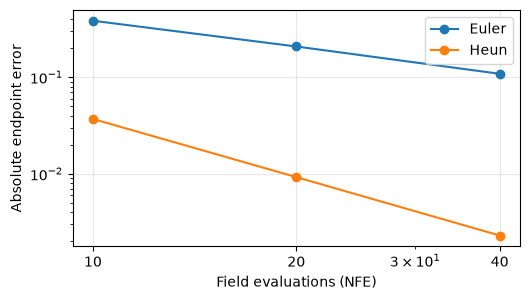

In [4]:
def solve_reference(
    field: Callable[[Tensor, float], Tensor],
    initial: Tensor,
    steps: int,
    *,
    heun: bool,
) -> tuple[Tensor, int]:
    """在 [0,1] 进行等步长参考积分，返回末状态和速度场实际求值次数。"""
    if steps < 1:
        raise ValueError("steps must be positive")
    state, evaluations = initial, 0
    h = 1.0 / steps
    for i in range(steps):
        t = i / steps
        k1 = field(state, t)
        evaluations += 1
        if heun:
            k2 = field(state + h * k1, (i + 1) / steps)
            evaluations += 1
            state = state + (h / 2.0) * (k1 + k2)
        else:
            state = state + h * k1
    return state, evaluations


def time_field(
    state: Tensor,
    time: float,
) -> Tensor:
    """返回解析题 dx/dt = 2tx 的速度，形状与 state 相同。"""
    return 2.0 * time * state


initial = torch.tensor([1.0], dtype=dtype)
euler_two, _ = solve_reference(time_field, initial, 2, heun=False)
heun_two, _ = solve_reference(time_field, initial, 2, heun=True)
assert math.isclose(euler_two.item(), 1.5) and math.isclose(heun_two.item(), 2.5)

budgets = [10, 20, 40]
errors = {"Euler": [], "Heun": []}
print("NFE | Euler steps / abs error | Heun steps / abs error")
for budget in budgets:
    euler, n_e = solve_reference(time_field, initial, budget, heun=False)
    heun, n_h = solve_reference(time_field, initial, budget // 2, heun=True)
    assert n_e == n_h == budget
    euler_error = abs(euler.item() - math.e)
    heun_error = abs(heun.item() - math.e)
    errors["Euler"].append(euler_error)
    errors["Heun"].append(heun_error)
    print(
        f"{budget:3d} | {budget:2d} / {euler_error:.6f}             "
        f"| {budget // 2:2d} / {heun_error:.6f}"
    )

fig, ax = plt.subplots(figsize=(5.4, 3.1))
for name, values in errors.items():
    ax.loglog(budgets, values, "o-", label=name)
ax.set(xlabel="Field evaluations (NFE)", ylabel="Absolute endpoint error", xticks=budgets)
ax.set_xticklabels(budgets)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

误差是相对解析解 $e$ 的绝对终点误差。预算翻倍后，Euler 误差大致减半，Heun 在逐渐接近二阶的下降趋势。这个例子的 Heun 在相同 NFE 下误差更小。网络预测不准、速度场不够平滑，或各时段难度差异很大时，实际图像质量排序仍需单独测量。

### **3. 只给新噪声，走完整条二维采样链**

这一轮另用种子 4102 生成新起点。只调用第三章的解析边际速度，走完 $t=0\to1$。同一批起点用 Euler 20 步和 Heun 10 步，双方都调用场 20 次。点云和横纵坐标的均值、标准差用于检查结果。目标分布的均值为 $(0,0)$，纵向标准差为 $\sigma=0.45$，横向方差按全方差公式为 $4+\sigma^2=4.2025$，所以横向标准差约 $2.050$。

右两幅图的点未绑定第一章的任何终点。这里「生成」指把独立噪声送入已知解析场，得到连续二维样本。

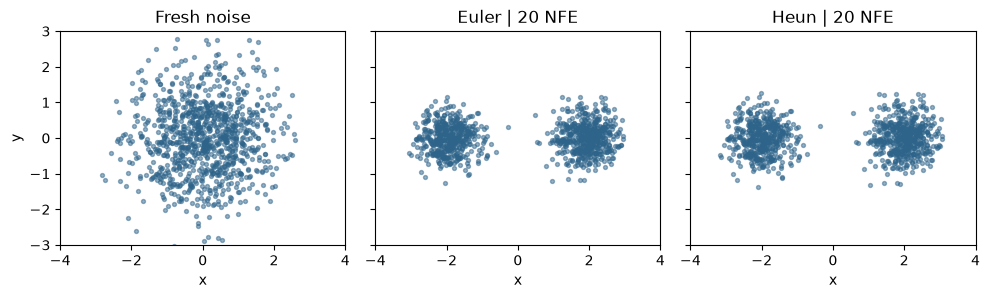

seed=4102 | 1000 independent starts | target std=(2.050, 0.450)
Euler | 20 NFE  mean=(0.099, 0.001), std=(1.979, 0.409)
Heun | 20 NFE   mean=(0.102, 0.001), std=(2.037, 0.444)


In [5]:
sample_rng = torch.Generator(device="cpu").manual_seed(4102)
fresh_noise = torch.randn(1000, 2, generator=sample_rng, dtype=dtype)
euler_cloud, n_e = solve_reference(mixture_field, fresh_noise, 20, heun=False)
heun_cloud, n_h = solve_reference(mixture_field, fresh_noise, 10, heun=True)
assert n_e == n_h == 20
assert torch.isfinite(euler_cloud).all() and torch.isfinite(heun_cloud).all()

fig, axes = plt.subplots(1, 3, figsize=(10, 3.0), sharex=True, sharey=True)
panels = [
    ("Fresh noise", fresh_noise),
    ("Euler | 20 NFE", euler_cloud),
    ("Heun | 20 NFE", heun_cloud),
]
for ax, (name, points) in zip(axes, panels, strict=True):
    ax.scatter(*points.T, s=8, alpha=0.5, color="#2e648a")
    ax.set(title=name, xlim=(-4, 4), ylim=(-3, 3), xlabel="x")
    ax.set_aspect("equal")
axes[0].set_ylabel("y")
fig.tight_layout()
plt.show()

print(f"seed=4102 | {len(fresh_noise)} independent starts | target std=(2.050, 0.450)")
for name, cloud in panels[1:]:
    mx, my = cloud.mean(dim=0).tolist()
    sx, sy = cloud.std(dim=0, unbiased=False).tolist()
    print(f"{name:15} mean=({mx:.3f}, {my:.3f}), std=({sx:.3f}, {sy:.3f})")

观察两个簇是否出现、尾部是否明显变形，再比较经验标准差与理论值。有限样本本身带来均值和方差波动。解析例子可以说明采样器和路径方向能工作，也能说明一团分布怎样分成两簇。这里没有训练神经网络，不能用这几张图来估计模型拟合能力、真实图像质量或 GPU 性能。

## **五、把 Flow 和学过的扩散方法放在一张图里**

### **1. 区分路径、预测目标与采样器**

这三个层面可以分别改变：路径规定各时刻是什么分布，目标规定网络输出表示什么，采样器规定怎样从噪声走向数据。以 $z$ 为干净样本，扩散的直接加噪写作 $x_\tau=a_\tau z+s_\tau\epsilon$，其中 VP（Variance Preserving，方差保持）日程满足 $a_\tau^2+s_\tau^2=1$，例如 DDPM 的 $a_\tau=\sqrt{\bar\alpha_\tau}$。扩散前向时间 $\tau$ 从数据指向噪声，本课 Flow 时间 $t$ 从噪声指向数据。

| 概念 | 常见模型输出或所需量 | 怎样生成 |
| --- | --- | --- |
| S1 DDPM | 用网络预测加噪时抽的 $\epsilon$，据此构造反向转移的均值 | 逆着离散扩散索引采样，通常每步有随机项 |
| DDIM（$\eta=0$） | 可沿用同一个噪声预测器，再恢复预测的 $\widehat z$ | 在所选时间子序列上用确定性更新，仍从噪声开始 |
| 扩散的 $v$ 参数化 | 目标可写成 $v_\tau^{\mathrm{VP}}=a_\tau\epsilon-s_\tau z$ | 这是扩散下的预测坐标，先按调度器定义换算再采样 |
| Probability Flow ODE | 给定扩散 SDE 的漂移、扩散系数及边际 score，可写出确定性速度场 | 用确定性 ODE 求解器积分，理想情况下匹配对应 SDE 的时刻边际 |
| 本课线性 Flow Matching | 用 $z-\epsilon$ 作为配对标签，回归 $v_\theta(x_t,t,c_{\mathrm{txt}})$ | 直接对速度从 $0$ 积到 $1$，例如 Euler 或 Heun |

扩散的 $v^{\mathrm{VP}}$ 和 Flow 的配对速度都能写成数据、噪声的线性组合，但系数和时间坐标不同。举例，若 $a_\tau=\cos\varphi(\tau)$、$s_\tau=\sin\varphi(\tau)$，固定两端点求导有 $\frac{\mathrm d x_\tau}{\mathrm d\tau}=\varphi'(\tau)(a_\tau\epsilon-s_\tau z)$。可见 $v^{\mathrm{VP}}$ 在此参数化下与轨迹导数有关，还要乘角度变化率；这与本课线性路径的 $z-\epsilon$ 是两回事。也不能把旧 $\epsilon$ 预测的 checkpoint 直接交给本课 Euler 更新。[DDPM](https://arxiv.org/abs/2006.11239v2) · [DDIM 第 4 节](https://arxiv.org/abs/2010.02502v4) · [Progressive Distillation 第 4 节及附录 D](https://arxiv.org/abs/2202.00512v2)

### **2. Probability Flow ODE 为什么也叫 Flow**

Score 指密度对数的空间梯度 $\nabla_x\log p_\tau(x)$。在 $\mathrm dX=f(X,\tau)\mathrm d\tau+g(\tau)\mathrm dW$ 中，$f$ 是漂移，$g$ 是只依赖时间的标量扩散系数，$W$ 是标准布朗运动。其密度服从 Fokker–Planck 方程

$$\partial_\tau p_\tau=-\nabla\cdot(f p_\tau)+\tfrac12 g(\tau)^2\Delta p_\tau$$

当密度足够光滑且正时，$\nabla p_\tau=p_\tau\nabla\log p_\tau$。于是可把扩散项并进散度，改写为

$$\partial_\tau p_\tau=-\nabla\cdot\left[\left(f-\tfrac12 g(\tau)^2\nabla\log p_\tau\right)p_\tau\right]$$

括号里的速度由漂移与 score 组成，等式是与对应 ODE 相同的连续性方程。这个构造解释了为什么扩散也有确定性的概率流。它从已有扩散路径和 score 出发；本课 FM 先规定线性配对路径，再通过条件速度回归训练 ODE 的速度。两者都能实现确定性输运，选择扩散概率路径来做 FM 也是可能的。DDIM 的确定性离散更新与扩散 ODE 有联系，其任意有限步结果不必和某个 ODE 求解器完全相同。比较时要说清所用日程、时间方向、模型输出及离散方法。[Score-SDE 第 4.3 节和附录 D.1](https://arxiv.org/abs/2011.13456) · [Flow Matching 第 4–5 节](https://arxiv.org/abs/2210.02747v2)

## **六、独立练手：四个函数连接训练和采样**

### **1. 合上参考，自己写路径和更新**

以下练习限定为四个张量函数。写在本课代码单元，运行下一格的检查。前面的参考实验使用自己的解析公式与参考循环，不调用这些函数。练习中的待实现异常只用于显示状态，不会切换到参考实现。

| 函数 | 输入契约 | 输出契约 |
| --- | --- | --- |
| `flow_interpolate` | 同形浮点 `noise, clean [b,*z]`，`time [b]`，逐样本时间在 $[0,1]$ | 同形 $x_t$，保留梯度 |
| `flow_target_velocity` | 同形浮点 `noise, clean [b,*z]` | 同形配对速度，顺序从 noise 到 clean |
| `euler_step` | 同形 `state, velocity`，正时间增量 `dt` | 新的同形状态，保留传入张量 |
| `heun_step` | `field(state,time)`、当前状态、标量时间、正步长 | 新的同形状态。按顺序求值两次 |

`*z` 表示任意特征轴，例如二维点的一个坐标轴、图像 latent 的三个轴。先写插值和配对速度，再写 Euler，最后写 Heun。Heun 可调用你自己的 Euler 做预测。先验算端点，再看梯度和非自治场。接口与仓库现有预留函数的对应关系见 [Flow 个人核心接口](src/minigen/objectives/flow_objective.py)，其中 `linear_path(clean, noise, time)` 将本练习前两项合成一项，注意参数顺序。此处练习独立运行。

In [6]:
def flow_interpolate(
    noise: Tensor,
    clean: Tensor,
    time: Tensor,
) -> Tensor:
    """练习：按每个样本的时间构造同形路径点。"""
    raise NotImplementedError("flow_interpolate")


def flow_target_velocity(
    noise: Tensor,
    clean: Tensor,
) -> Tensor:
    """练习：返回噪声指向数据的同形监督向量。"""
    raise NotImplementedError("flow_target_velocity")


def euler_step(
    state: Tensor,
    velocity: Tensor,
    dt: float,
) -> Tensor:
    """练习：使用当前速度更新一步，返回同形状态。"""
    raise NotImplementedError("euler_step")


def heun_step(
    field: Callable[[Tensor, float], Tensor],
    state: Tensor,
    time: float,
    dt: float,
) -> Tensor:
    """练习：先预测右端，再平均左右端速度更新一步。"""
    raise NotImplementedError("heun_step")

### **2. 用独立的常量和解析答案验收**

测试期望值来自端点、手算和梯度恒等式，独立于参考求解器。第一个测试用 `b=w=3` 识别能广播但广播错轴的实现，并对干净端、噪声端和时间分别核对梯度。最后一个测试记录两次场调用，右端既要用预测位置，也要用更新后的时间。未填写会显示待完成，错误实现会在对应断言停止。

In [7]:
def check_interpolation() -> None:
    """检查四维逐样本广播、端点、有限值和三个输入的梯度。"""
    shape = (3, 1, 2, 3)
    start = torch.full(shape, -2.0, dtype=dtype, requires_grad=True)
    end = torch.full(shape, 6.0, dtype=dtype, requires_grad=True)
    times = torch.tensor([0.0, 0.25, 1.0], dtype=dtype, requires_grad=True)
    result = flow_interpolate(start, end, times)
    expected = torch.stack((torch.full_like(start[0], -2), torch.zeros_like(start[1]), end[2]))
    assert result.shape == shape and torch.isfinite(result).all()
    torch.testing.assert_close(result, expected)
    result.sum().backward()
    for i, t in enumerate((0.0, 0.25, 1.0)):
        torch.testing.assert_close(start.grad[i], torch.full_like(start[i], 1.0 - t))
        torch.testing.assert_close(end.grad[i], torch.full_like(end[i], t))
    torch.testing.assert_close(times.grad, torch.full_like(times, 48.0))


def check_target_velocity() -> None:
    """检查方向、形状、两份输入的梯度。"""
    start = torch.tensor([[-1.0, 2.0], [2.0, -1.0]], dtype=dtype, requires_grad=True)
    end = torch.tensor([[3.0, 0.0], [1.0, 1.0]], dtype=dtype, requires_grad=True)
    result = flow_target_velocity(start, end)
    torch.testing.assert_close(result, torch.tensor([[4.0, -2.0], [-1.0, 2.0]], dtype=dtype))
    result.sum().backward()
    torch.testing.assert_close(start.grad, -torch.ones_like(start))
    torch.testing.assert_close(end.grad, torch.ones_like(end))


def check_euler() -> None:
    """用手算位移验证正步长、常速度到达终点以及输入保留。"""
    state = torch.tensor([[-1.0, 2.0]], dtype=dtype)
    velocity = torch.tensor([[4.0, -2.0]], dtype=dtype)
    torch.testing.assert_close(
        euler_step(state, velocity, 0.25), torch.tensor([[0.0, 1.5]], dtype=dtype)
    )
    torch.testing.assert_close(
        euler_step(state, velocity, 1.0), torch.tensor([[3.0, 0.0]], dtype=dtype)
    )
    torch.testing.assert_close(state, torch.tensor([[-1.0, 2.0]], dtype=dtype))


def check_heun() -> None:
    """核对非自治场两次求值的时间、位置及最终梯形更新。"""
    calls = []

    def traced_field(
        state: Tensor,
        time: float,
    ) -> Tensor:
        """记录求值输入，再返回 2tx。"""
        calls.append((state.item(), time))
        return 2.0 * time * state

    state = torch.tensor([1.25], dtype=dtype)
    result = heun_step(traced_field, state, 0.5, 0.5)
    assert calls == [(1.25, 0.5), (1.875, 1.0)], calls
    torch.testing.assert_close(result, torch.tensor([2.5], dtype=dtype))
    torch.testing.assert_close(state, torch.tensor([1.25], dtype=dtype))


checks = {
    "flow_interpolate": check_interpolation,
    "flow_target_velocity": check_target_velocity,
    "euler_step": check_euler,
    "heun_step": check_heun,
}
for name, check in checks.items():
    try:
        check()
    except NotImplementedError:
        print(f"{name}: 待完成")
    else:
        print(f"{name}: 通过")

flow_interpolate: 待完成
flow_target_velocity: 待完成
euler_step: 待完成
heun_step: 待完成


## **七、合上代码前的自测**

<details>
<summary>1. 为什么两条训练线在同一点的速度可以冲突，但模型仍有正确答案？</summary>

平方回归的输入固定后，最优输出是给定这些信息的速度条件均值。不同配对引入的方差是不可消除的项。用这个均值演化的 ODE 可以在正则条件下匹配每个时刻的分布，无需重现配对线。

</details>

<details>
<summary>2. 为什么图像张量不能直接乘形状为 [b] 的时间？</summary>

广播从右侧对齐。若 $b=w$，代码甚至可以执行，却把时间乘到宽度轴。时间必须扩成 `[b,1,1,1]`，只沿特征轴共享。

</details>

<details>
<summary>3. 同一初值、同为 20 分支等价 NFE，双分支 CFG 时两种方法各走几步？</summary>

Euler 每步一组速度，每组两分支，因此走 10 步。Heun 每步两组速度、共四分支，因此走 5 步。合批可能让两者都只做 10 次主干调用，但每次前向都处理两分支。

</details>

<details>
<summary>4. 我可以把扩散的 v 预测或 DDPM 的噪声直接放进这里的 ODE 吗？</summary>

先看输出定义和时间坐标。旧 DDPM 输出是加噪时的噪声。VP 的 $v$ 是另一种扩散参数化，固定端点时还需乘相应时间坐标的变化率才是该路径导数。本课直接回归线性路径下的速度。要复用模型，必须先推导与其日程匹配的转换和积分式。

</details>

<details>
<summary>5. 用 Heun 能否修复速度模型始终预测错方向？</summary>

Heun 可以减小对给定速度场的离散误差。如果场本身方向错了，更准确地积分它仍会走错。解析场实验先验算求解器，训练后再用同一初值、参考条件和终点统计检查模型误差。

</details>

本课的验收对象是路径公式、MSE 梯度、解析 ODE 与二维点云。个人四项练习在实际实现并运行前都保留待完成。S4-02 会把二维坐标换成 VAE latent，把空条件换成可带 mask 的文本 token，并追踪模型输出、训练和采样中的同一个速度契约。

延伸阅读建议先读 [本地 Flow Matching 论文](../papers/Flow_Matching_for_Generative_Modeling_2210.02747v2.pdf) 的第 3–5 节。对照本课第三章看边际场如何由条件场平均得到，再回到第四章分别检查「场由何而来」和「用几次场求值积分」。